# Plots for Wood, Graber & Newton (2021) - Superconducting phases in a two-component microscale model of neutron star cores

In [1]:
#!/usr/bin/env python
"""Plots for Section III and IV of Wood, Graber & Newton (2021)"""

__author__ = "Vanessa Graber"
__copyright__ = "Copyright 2020"
__credits__ = ["Vanessa Graber"]
__license__ = "MIT"
__maintainer__ = "Vanessa Graber"
__email__ = "graber@ice.csic.es"

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rc

## Plotting adjustments

In [3]:
%matplotlib inline

# Set `usetex=False' if you do not have LaTeX installed.
rc("text", usetex=True)
rc("font", family="serif")
mpl.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}"

In [4]:
SMALL_SIZE = 14
MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=MEDIUM_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=MEDIUM_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [5]:
width = 6.8
# golden = 1.61803398875
# height = width / golden
height = 5.0

In [6]:
colours = [
    "#d32f2f",
    "#7b1fa2",
    "#303f9f",
    "#0097a7",
    "#689f38",
    "#ffa000",
    "#B8B8B8",
    "#484848",
]
lines = [[], [1, 2], [2, 1], [4, 1], [8, 1], [4, 1, 2, 1]]

## Equilibrium composition

In [7]:
data_LNS = pd.read_csv("../examples/data/parameters_LNS.txt", header=[0, 1])
data_NRAPR = pd.read_csv("../examples/data/parameters_NRAPR.txt", header=[0, 1])
data_Skchi450 = pd.read_csv("../examples/data/parameters_Skchi450.txt", header=[0, 1])
data_SLy4 = pd.read_csv("../examples/data/parameters_SLy4.txt", header=[0, 1])
data_SQMC700 = pd.read_csv("../examples/data/parameters_SQMC700.txt", header=[0, 1])
data_Ska35s20 = pd.read_csv("../examples/data/parameters_Ska35s20.txt", header=[0, 1])

In [8]:
data_LNS.tail()

,n_b,rho_b,n_n,n_p,lambda,lambda_star,xi_n,xi_p,kappa,R,epsilon,m_eff_relL_n,m_eff_relL_p,A_nn,A_pp,A_np
,[1/fm**3],[g/cm**3],[1/fm**3],[1/fm**3],[cm],[cm],[cm],[cm],[],[],[],[],[],[MeV fm**5],[MeV fm**5],[MeV fm**5]
495,0.595671,9.891355e+14,0.539520,0.056152,3.027803e-12,2.064955e-12,1.613615e-11,2.821295e-11,0.107320,1.748431,0.104077,0.791803,0.461918,-86.360952,-2.113521,24.505608
496,0.596754,9.909325e+14,0.540524,0.056229,3.025717e-12,2.062505e-12,1.620576e-11,2.849777e-11,0.106174,1.758497,0.104027,0.791533,0.461457,-86.506849,-2.165132,24.359001
497,0.597836,9.927294e+14,0.541529,0.056306,3.023643e-12,2.060067e-12,1.627580e-11,2.878544e-11,0.105041,1.768604,0.103977,0.791263,0.460997,-86.652729,-2.216551,24.212430
498,0.598918,9.945264e+14,0.542535,0.056383,3.021582e-12,2.057640e-12,1.634628e-11,2.907600e-11,0.103920,1.778753,0.103926,0.790993,0.460538,-86.798594,-2.267778,24.065896
499,0.600000,9.963234e+14,0.543540,0.056460,3.019534e-12,2.055224e-12,1.641721e-11,2.936947e-11,0.102812,1.788944,0.103874,0.790724,0.460079,-86.944445,-2.318814,23.919398


In [9]:
n_b = data_LNS["n_b"].values
rho_b_log = np.log10(data_LNS["rho_b"]).values
rho_b = data_LNS["rho_b"].values

In [10]:
x_p_LNS = data_LNS["n_p"].values / n_b
x_p_NRAPR = data_NRAPR["n_p"].values / n_b
x_p_Skchi450 = data_Skchi450["n_p"].values / n_b
x_p_SLy4 = data_SLy4["n_p"].values / n_b
x_p_SQMC700 = data_SQMC700["n_p"].values / n_b
x_p_Ska35s20 = data_Ska35s20["n_p"].values / n_b

In [11]:
x_n_LNS = data_LNS["n_n"].values / n_b
x_n_NRAPR = data_NRAPR["n_n"].values / n_b
x_n_Skchi450 = data_Skchi450["n_n"].values / n_b
x_n_SLy4 = data_SLy4["n_n"].values / n_b
x_n_SQMC700 = data_SQMC700["n_n"].values / n_b
x_n_Ska35s20 = data_Ska35s20["n_n"].values / n_b

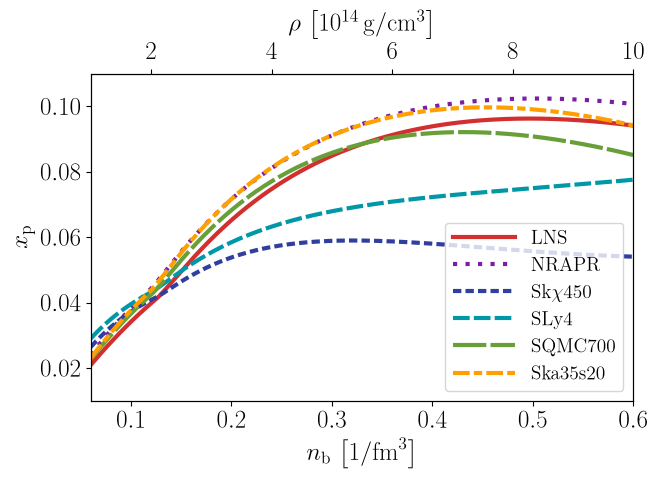

In [12]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(n_b, x_p_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0])
ax.plot(
    n_b, x_p_NRAPR, "-", color=colours[1], linewidth=3, label=r"NRAPR", dashes=lines[1]
)
ax.plot(
    n_b,
    x_p_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b, x_p_SLy4, "-", color=colours[3], linewidth=3, label=r"SLy4", dashes=lines[3]
)
ax.plot(
    n_b,
    x_p_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    x_p_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 0.11
ax.set_ylim(0.01, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$x_{\rm p}$")

plt.legend(loc=4, handlelength=3.2)

secax = ax.twiny()
secax.plot(rho_b * 1e-14, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/proton_fractions.pdf", dpi=1000, bbox_inches="tight")
plt.show()

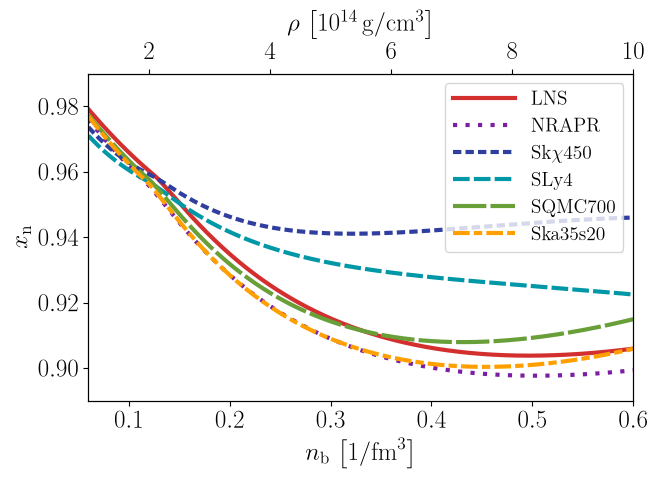

In [13]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(n_b, x_n_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0])
ax.plot(
    n_b, x_n_NRAPR, "-", color=colours[1], linewidth=3, label=r"NRAPR", dashes=lines[1]
)
ax.plot(
    n_b,
    x_n_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b, x_n_SLy4, "-", color=colours[3], linewidth=3, label=r"SLy4", dashes=lines[3]
)
ax.plot(
    n_b,
    x_n_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    x_n_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 0.99
ax.set_ylim(0.89, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$x_{\rm n}$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(rho_b * 1e-14, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/neutron_fractions.pdf", dpi=1000, bbox_inches="tight")
plt.show()

## Superfluid parameters

In [14]:
data_gaps = pd.read_csv("../examples/data/energy_gaps.txt", header=[0, 1])

In [15]:
data_gaps.head()

,k_F,Delta_p,Delta_n
,[1/fm],[MeV],[MeV]
0,0.00,NaN,NaN
1,0.01,0.000596,NaN
2,0.02,0.002367,NaN
3,0.03,0.005284,NaN
4,0.04,0.009322,NaN


### Gaps as function of Fermi number

In [16]:
k_F = data_gaps["k_F"].values
Delta_p = data_gaps["Delta_p"].values
Delta_n = data_gaps["Delta_n"].values

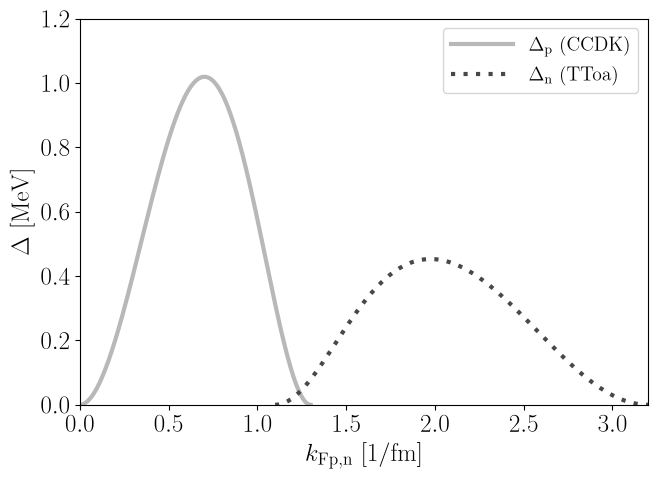

In [17]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    k_F,
    Delta_p,
    "-",
    color=colours[6],
    linewidth=3,
    label=r"$\Delta_{\rm p}$ (CCDK)",
    dashes=lines[0],
)
ax.plot(
    k_F,
    Delta_n,
    "-",
    color=colours[7],
    linewidth=3,
    label=r"$\Delta_{\rm n}$ (TToa)",
    dashes=lines[1],
)

ax.set_xlim(0.0, 3.2)
ax.set_ylim(0.0, 1.2)
ax.set_xlabel(r"$k_{\rm F p,n}$ [${\rm 1/fm}$]")
ax.set_ylabel(r"$\Delta$ [${\rm MeV}$]")

plt.legend(loc=1, handlelength=3.2)

plt.tight_layout()

plt.savefig("../examples/plots/energy_gaps.pdf", dpi=1000, bbox_inches="tight")
plt.show()

### Gaps as function of density

In [18]:
Delta_p_NRAPR = data_NRAPR["Delta_p"].values
Delta_n_NRAPR = data_NRAPR["Delta_n"].values
Delta_p_Skchi450 = data_Skchi450["Delta_p"].values
Delta_n_Skchi450 = data_Skchi450["Delta_n"].values
Delta_p_SLy4 = data_SLy4["Delta_p"].values
Delta_n_SLy4 = data_SLy4["Delta_n"].values

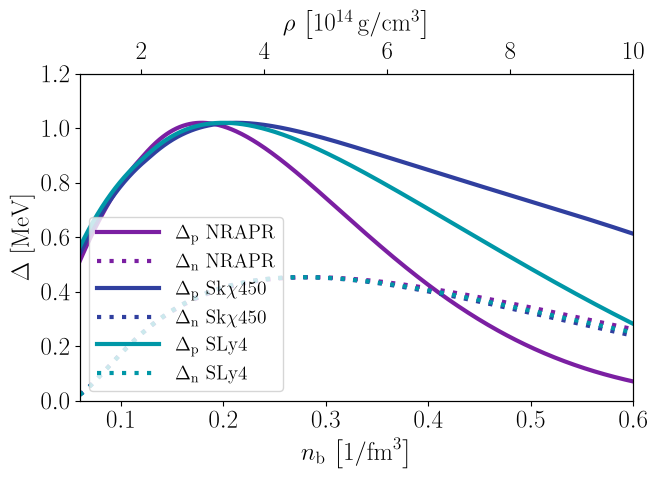

In [19]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    Delta_p_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$\Delta_{\rm p}$ NRAPR",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Delta_n_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$\Delta_{\rm n}$ NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    Delta_p_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$\Delta_{\rm p}$ Sk$\chi450$",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Delta_n_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$\Delta_{\rm n}$ Sk$\chi450$",
    dashes=lines[1],
)
ax.plot(
    n_b,
    Delta_p_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$\Delta_{\rm p}$ SLy4",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Delta_n_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$\Delta_{\rm n}$ SLy4",
    dashes=lines[1],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 1.2
ax.set_ylim(0.0, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\Delta$ [${\rm MeV}$]")

plt.legend(loc=3, handlelength=3.2)

secax = ax.twiny()
secax.plot(rho_b * 1e-14, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/energy_gaps_density.pdf", dpi=1000, bbox_inches="tight")
plt.show()

### Temperature as function of density

In [20]:
k_B = 8.617330 * 1e-11  # [MeV/K]
c_singlet = 0.567
c_triplet = 0.118

Tc_p_NRAPR = c_singlet * Delta_p_NRAPR / k_B
Tc_n_NRAPR = c_triplet * Delta_n_NRAPR / k_B
Tc_p_Skchi450 = c_singlet * Delta_p_Skchi450 / k_B
Tc_n_Skchi450 = c_triplet * Delta_n_Skchi450 / k_B
Tc_p_SLy4 = c_singlet * Delta_p_SLy4 / k_B
Tc_n_SLy4 = c_triplet * Delta_n_SLy4 / k_B

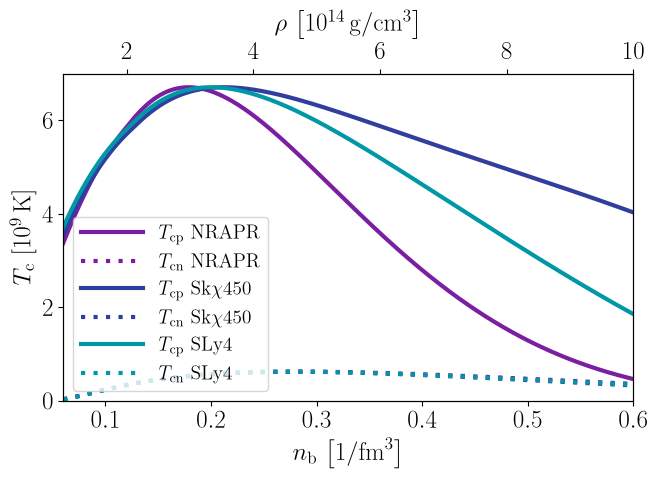

In [21]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    Tc_p_NRAPR * 1e-9,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$T_{\rm cp}$ NRAPR",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Tc_n_NRAPR * 1e-9,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$T_{\rm cn}$ NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    Tc_p_Skchi450 * 1e-9,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$T_{\rm cp}$ Sk$\chi450$",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Tc_n_Skchi450 * 1e-9,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$T_{\rm cn}$ Sk$\chi450$",
    dashes=lines[1],
)
ax.plot(
    n_b,
    Tc_p_SLy4 * 1e-9,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$T_{\rm cp}$ SLy4",
    dashes=lines[0],
)
ax.plot(
    n_b,
    Tc_n_SLy4 * 1e-9,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$T_{\rm cn}$ SLy4",
    dashes=lines[1],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 7
ax.set_ylim(0.0, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$T_{\rm c}$ [$10^9 \, {\rm K}$]")

plt.legend(loc=3, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/Tc_density.pdf", dpi=1000, bbox_inches="tight")
plt.show()

### Coherence lengths

In [22]:
xi_p_NRAPR = data_NRAPR["xi_p"].values
xi_n_NRAPR = data_NRAPR["xi_n"].values
xi_p_Skchi450 = data_Skchi450["xi_p"].values
xi_n_Skchi450 = data_Skchi450["xi_n"].values
xi_p_SLy4 = data_SLy4["xi_p"].values
xi_n_SLy4 = data_SLy4["xi_n"].values

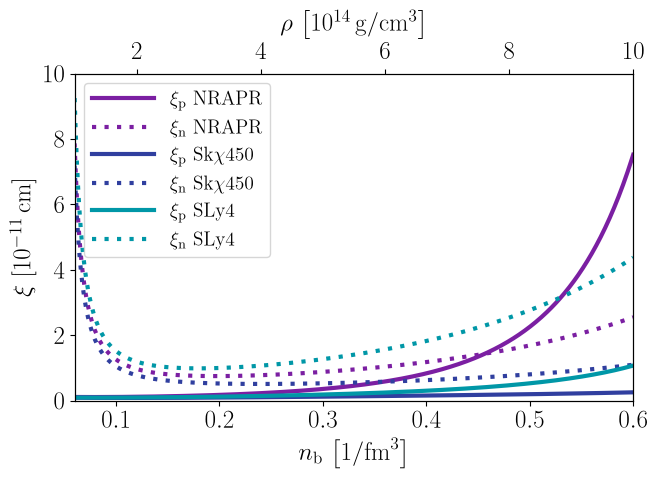

In [23]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    xi_p_NRAPR * 1e11,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$\xi_{\rm p}$ NRAPR",
    dashes=lines[0],
)
ax.plot(
    n_b,
    xi_n_NRAPR * 1e11,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"$\xi_{\rm n}$ NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    xi_p_Skchi450 * 1e11,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$\xi_{\rm p}$ Sk$\chi450$",
    dashes=lines[0],
)
ax.plot(
    n_b,
    xi_n_Skchi450 * 1e11,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"$\xi_{\rm n}$ Sk$\chi450$",
    dashes=lines[1],
)
ax.plot(
    n_b,
    xi_p_SLy4 * 1e11,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$\xi_{\rm p}$ SLy4",
    dashes=lines[0],
)
ax.plot(
    n_b,
    xi_n_SLy4 * 1e11,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"$\xi_{\rm n}$ SLy4",
    dashes=lines[1],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 10
ax.set_ylim(0.0, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\xi$ [$10^{-11} \, {\rm cm}$]")

plt.legend(loc=2, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig(
    "../examples/plots/coherence_lengths_density.pdf", dpi=1000, bbox_inches="tight"
)
plt.show()

### London length

In [24]:
lambda_NRAPR = data_NRAPR["lambda"].values
lambda_Skchi450 = data_Skchi450["lambda"].values
lambda_SLy4 = data_SLy4["lambda"].values

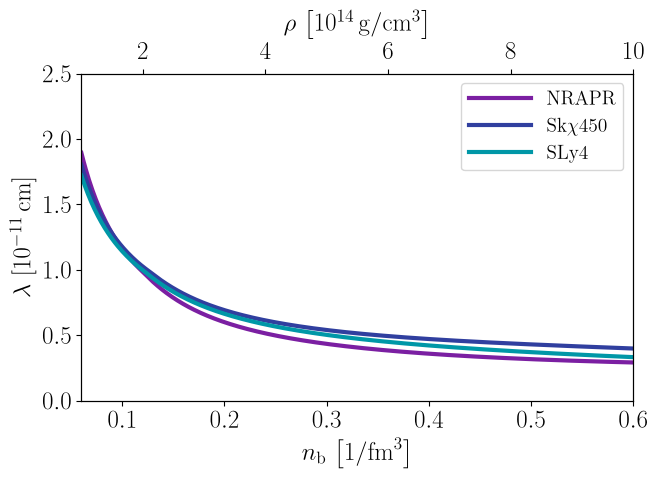

In [25]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    lambda_NRAPR * 1e11,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[0],
)
ax.plot(
    n_b,
    lambda_Skchi450 * 1e11,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi450$",
    dashes=lines[0],
)
ax.plot(
    n_b,
    lambda_SLy4 * 1e11,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[0],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 2.5
ax.set_ylim(0.0, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\lambda$ [$10^{-11} \, {\rm cm}$]")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig(
    "../examples/plots/London_length_density.pdf", dpi=1000, bbox_inches="tight"
)
plt.show()

## Dimensionless parameters

In [26]:
kappa_LNS = data_LNS["kappa"].values
kappa_NRAPR = data_NRAPR["kappa"].values
kappa_Skchi450 = data_Skchi450["kappa"].values
kappa_SLy4 = data_SLy4["kappa"].values
kappa_SQMC700 = data_SQMC700["kappa"].values
kappa_Ska35s20 = data_Ska35s20["kappa"].values

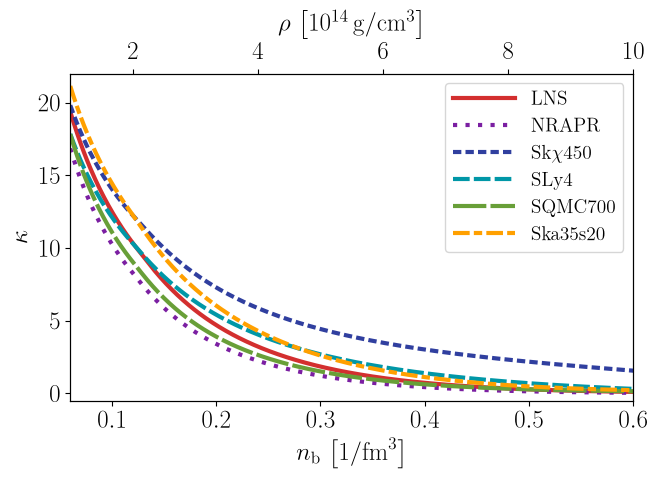

In [27]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, kappa_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    kappa_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    kappa_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b, kappa_SLy4, "-", color=colours[3], linewidth=3, label=r"SLy4", dashes=lines[3]
)
ax.plot(
    n_b,
    kappa_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    kappa_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 22
ax.set_ylim(-0.5, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\kappa$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/kappa.pdf", dpi=1000, bbox_inches="tight")
plt.show()

In [28]:
kappa_star_LNS = data_LNS["lambda_star"].values / data_LNS["xi_p"].values
kappa_star_NRAPR = data_NRAPR["lambda_star"].values / data_NRAPR["xi_p"].values
kappa_star_Skchi450 = data_Skchi450["lambda_star"].values / data_Skchi450["xi_p"].values
kappa_star_SLy4 = data_SLy4["lambda_star"].values / data_SLy4["xi_p"].values
kappa_star_SQMC700 = data_SQMC700["lambda_star"].values / data_SQMC700["xi_p"].values
kappa_star_Ska35s20 = data_Ska35s20["lambda_star"].values / data_Ska35s20["xi_p"].values

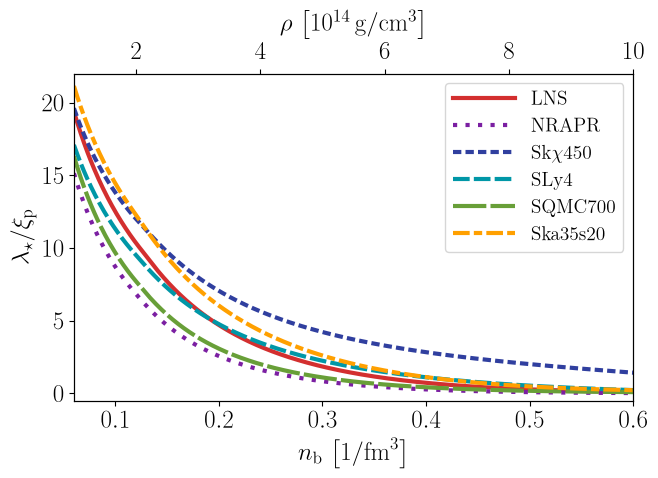

In [29]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, kappa_star_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    kappa_star_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    kappa_star_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    kappa_star_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    kappa_star_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    kappa_star_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 22
ax.set_ylim(-0.5, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\lambda_{\star} / \xi_{\rm p}$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/kappa_star.pdf", dpi=1000, bbox_inches="tight")
plt.show()

In [30]:
R_LNS = data_LNS["R"].values
R_NRAPR = data_NRAPR["R"].values
R_Skchi450 = data_Skchi450["R"].values
R_SLy4 = data_SLy4["R"].values
R_SQMC700 = data_SQMC700["R"].values
R_Ska35s20 = data_Ska35s20["R"].values

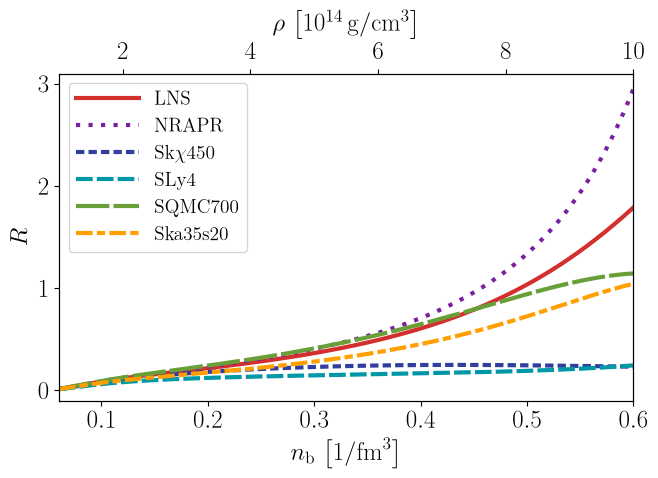

In [31]:
fig, ax = plt.subplots()
fig.set_size_inches(width * 1.027, height)

ax.plot(n_b, R_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0])
ax.plot(
    n_b, R_NRAPR, "-", color=colours[1], linewidth=3, label=r"NRAPR", dashes=lines[1]
)
ax.plot(
    n_b,
    R_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(n_b, R_SLy4, "-", color=colours[3], linewidth=3, label=r"SLy4", dashes=lines[3])
ax.plot(
    n_b,
    R_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    R_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 3.1
ax.set_ylim(-0.1, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$R$")

plt.legend(loc=2, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/R.pdf", dpi=1000, bbox_inches="tight")
plt.show()

In [32]:
epsilon_LNS = data_LNS["epsilon"].values
epsilon_NRAPR = data_NRAPR["epsilon"].values
epsilon_Skchi450 = data_Skchi450["epsilon"].values
epsilon_SLy4 = data_SLy4["epsilon"].values
epsilon_SQMC700 = data_SQMC700["epsilon"].values
epsilon_Ska35s20 = data_Ska35s20["epsilon"].values

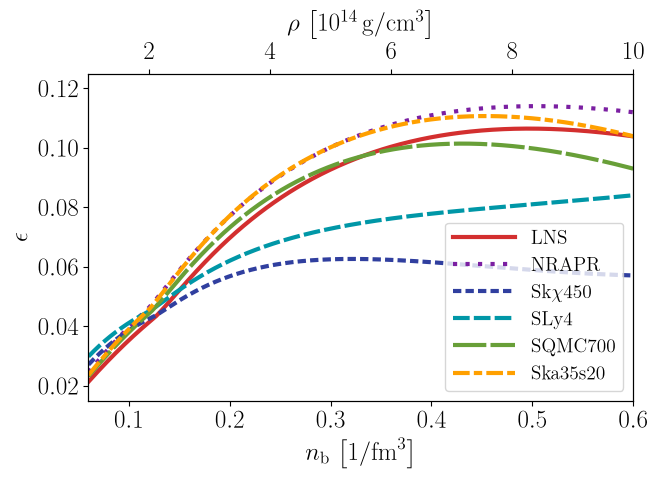

In [33]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, epsilon_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    epsilon_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    epsilon_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    epsilon_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    epsilon_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
ax.plot(
    n_b,
    epsilon_Ska35s20,
    "-",
    color=colours[5],
    linewidth=3,
    label=r"Ska35s20",
    dashes=lines[5],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 0.125
ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$\epsilon$")

plt.legend(loc=4, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/epsilon.pdf", dpi=1000, bbox_inches="tight")
plt.show()

## Relative effective masses

In [34]:
m_eff_Ln_LNS = data_LNS["m_eff_relL_n"].values
m_eff_Lp_LNS = data_LNS["m_eff_relL_p"].values
m_eff_Ln_NRAPR = data_NRAPR["m_eff_relL_n"].values
m_eff_Lp_NRAPR = data_NRAPR["m_eff_relL_p"].values
m_eff_Ln_SLy4 = data_SLy4["m_eff_relL_n"].values
m_eff_Lp_SLy4 = data_SLy4["m_eff_relL_p"].values

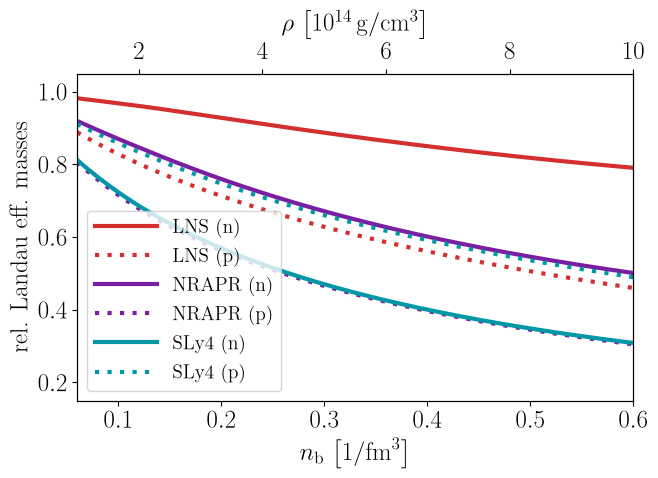

In [35]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    m_eff_Ln_LNS,
    "-",
    color=colours[0],
    linewidth=3,
    label=r"LNS (n)",
    dashes=lines[0],
)
ax.plot(
    n_b,
    m_eff_Lp_LNS,
    "-",
    color=colours[0],
    linewidth=3,
    label=r"LNS (p)",
    dashes=lines[1],
)
ax.plot(
    n_b,
    m_eff_Ln_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR (n)",
    dashes=lines[0],
)
ax.plot(
    n_b,
    m_eff_Lp_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR (p)",
    dashes=lines[1],
)
ax.plot(
    n_b,
    m_eff_Ln_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4 (n)",
    dashes=lines[0],
)
ax.plot(
    n_b,
    m_eff_Lp_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4 (p)",
    dashes=lines[1],
)

ax.set_xlim(0.06, 0.6)
upper_ylimit = 1.05
ax.set_ylim(0.15, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"rel. Landau eff. masses")

plt.legend(loc="best", handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/Landau_eff_masses.pdf", dpi=1000, bbox_inches="tight")
plt.show()

## Coefficients extended Thomas Fermi model

In [36]:
A_nn_LNS = data_LNS["A_nn"]["[MeV fm**5]"].values
A_nn_NRAPR = data_NRAPR["A_nn"]["[MeV fm**5]"].values
A_nn_Skchi450 = data_Skchi450["A_nn"]["[MeV fm**5]"].values
A_nn_SLy4 = data_SLy4["A_nn"]["[MeV fm**5]"].values
A_nn_SQMC700 = data_SQMC700["A_nn"]["[MeV fm**5]"].values
# A_nn_Ska35s20 = data_Ska35s20["A_nn"]["[MeV fm**5]"].values

In [37]:
A_pp_LNS = data_LNS["A_pp"]["[MeV fm**5]"].values
A_pp_NRAPR = data_NRAPR["A_pp"]["[MeV fm**5]"].values
A_pp_Skchi450 = data_Skchi450["A_pp"]["[MeV fm**5]"].values
A_pp_SLy4 = data_SLy4["A_pp"]["[MeV fm**5]"].values
A_pp_SQMC700 = data_SQMC700["A_pp"]["[MeV fm**5]"].values
# A_pp_Ska35s20 = data_Ska35s20["A_pp"]["[MeV fm**5]"].values

In [38]:
A_np_LNS = data_LNS["A_np"]["[MeV fm**5]"].values
A_np_NRAPR = data_NRAPR["A_np"]["[MeV fm**5]"].values
A_np_Skchi450 = data_Skchi450["A_np"]["[MeV fm**5]"].values
A_np_SLy4 = data_SLy4["A_np"]["[MeV fm**5]"].values
A_np_SQMC700 = data_SQMC700["A_np"]["[MeV fm**5]"].values
# A_np_Ska35s20 = data_Ska35s20["A_np"]["[MeV fm**5]"].values

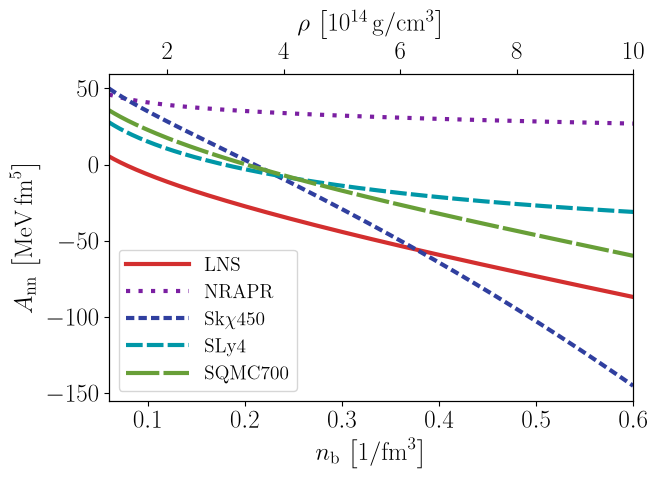

In [39]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, A_nn_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    A_nn_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    A_nn_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    A_nn_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    A_nn_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     A_nn_Ska35s20,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$A_{\rm nn}$ $\left[{\rm MeV} \, {\rm fm}^{5} \right]$")

plt.legend(loc=3, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_nn.pdf", dpi=1000, bbox_inches="tight")
plt.show()

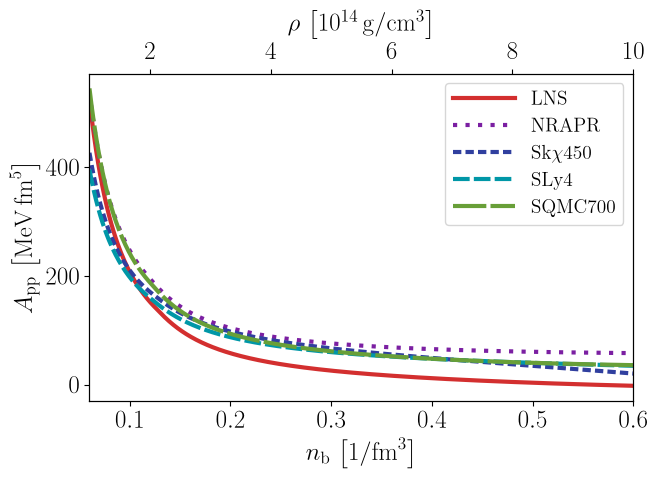

In [40]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, A_pp_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    A_pp_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    A_pp_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    A_pp_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    A_pp_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     A_pp_Ska35s20,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$A_{\rm pp}$ $\left[ {\rm MeV} \, {\rm fm}^{5} \right]$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_pp.pdf", dpi=1000, bbox_inches="tight")
plt.show()

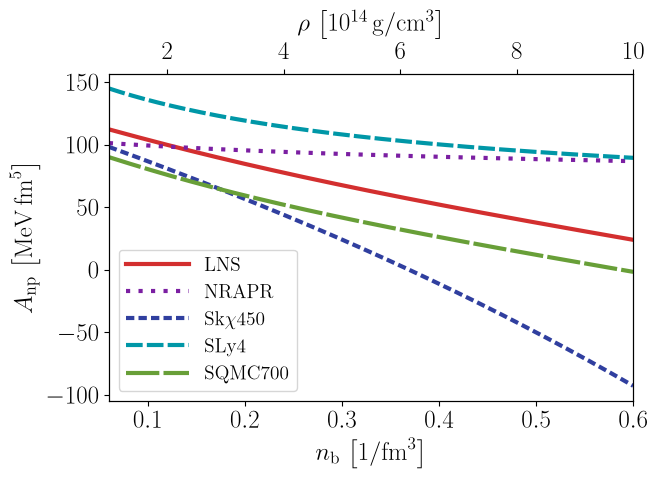

In [41]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b, A_np_LNS, "-", color=colours[0], linewidth=3, label=r"LNS", dashes=lines[0]
)
ax.plot(
    n_b,
    A_np_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    A_np_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    A_np_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    A_np_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     A_np_Ska35s20,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$A_{\rm np}$ $\left[ {\rm MeV} \, {\rm fm}^{5} \right]$")

plt.legend(loc=3, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_np.pdf", dpi=1000, bbox_inches="tight")
plt.show()

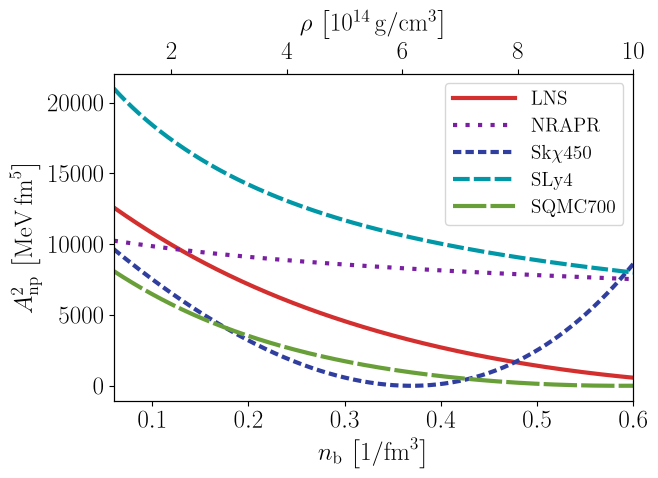

In [42]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    A_np_LNS**2,
    "-",
    color=colours[0],
    linewidth=3,
    label=r"LNS",
    dashes=lines[0],
)
ax.plot(
    n_b,
    A_np_NRAPR**2,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    A_np_Skchi450**2,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    A_np_SLy4**2,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    A_np_SQMC700**2,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     A_np_Ska35s20**2,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$A_{\rm np}^2$ $\left[ {\rm MeV} \, {\rm fm}^{5} \right]$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_np_squared.pdf", dpi=1000, bbox_inches="tight")
plt.show()

In [43]:
condition_1_LNS = A_nn_LNS + A_pp_LNS
condition_1_NRAPR = A_nn_NRAPR + A_pp_NRAPR
condition_1_Skchi450 = A_nn_Skchi450 + A_pp_Skchi450
condition_1_SLy4 = A_nn_SLy4 + A_pp_SLy4
condition_1_SQMC700 = A_nn_SQMC700 + A_pp_SQMC700
# condition_1_Ska35s20 = A_nn_Ska35s20 + A_pp_Ska35s20

In [44]:
condition_2_LNS = A_nn_LNS * A_pp_LNS - A_np_LNS**2 / 4.0
condition_2_NRAPR = A_nn_NRAPR * A_pp_NRAPR - A_np_NRAPR**2 / 4.0
condition_2_Skchi450 = A_nn_Skchi450 * A_pp_Skchi450 - A_np_Skchi450**2 / 4.0
condition_2_SLy4 = A_nn_SLy4 * A_pp_SLy4 - A_np_SLy4**2 / 4.0
condition_2_SQMC700 = A_nn_SQMC700 * A_pp_SQMC700 - A_np_SQMC700**2 / 4.0
# condition_2_Ska35s20 = A_nn_Ska35s20 * A_pp_Ska35s20 - A_np_Ska35s20**2 / 4.0

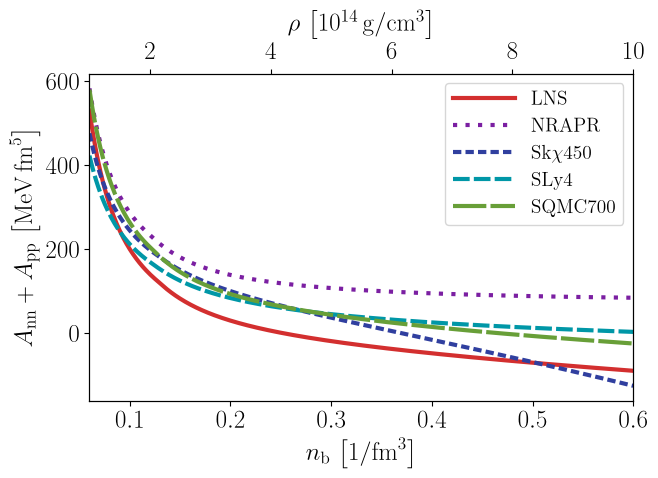

In [45]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    condition_1_LNS,
    "-",
    color=colours[0],
    linewidth=3,
    label=r"LNS",
    dashes=lines[0],
)
ax.plot(
    n_b,
    condition_1_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    condition_1_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    condition_1_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    condition_1_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     condition_1_Ska35s20,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(r"$A_{\rm nn} + A_{\rm pp}$ $\left[ {\rm MeV} \, {\rm fm}^{5} \right]$")

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_condition_1.pdf", dpi=1000, bbox_inches="tight")
plt.show()

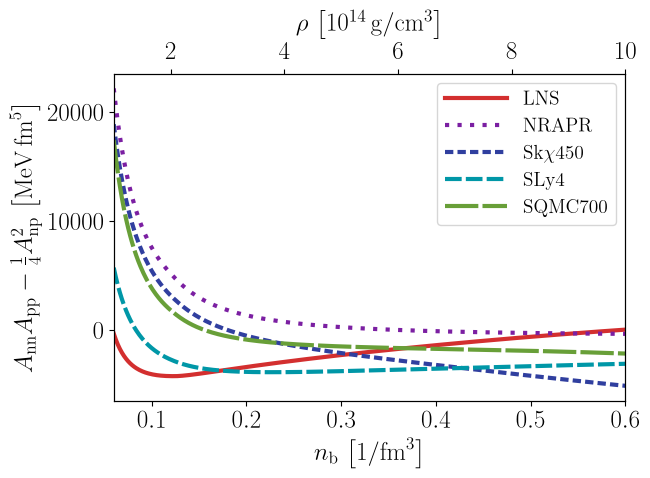

In [46]:
fig, ax = plt.subplots()
fig.set_size_inches(width, height)

ax.plot(
    n_b,
    condition_2_LNS,
    "-",
    color=colours[0],
    linewidth=3,
    label=r"LNS",
    dashes=lines[0],
)
ax.plot(
    n_b,
    condition_2_NRAPR,
    "-",
    color=colours[1],
    linewidth=3,
    label=r"NRAPR",
    dashes=lines[1],
)
ax.plot(
    n_b,
    condition_2_Skchi450,
    "-",
    color=colours[2],
    linewidth=3,
    label=r"Sk$\chi$450",
    dashes=lines[2],
)
ax.plot(
    n_b,
    condition_2_SLy4,
    "-",
    color=colours[3],
    linewidth=3,
    label=r"SLy4",
    dashes=lines[3],
)
ax.plot(
    n_b,
    condition_2_SQMC700,
    "-",
    color=colours[4],
    linewidth=3,
    label=r"SQMC700",
    dashes=lines[4],
)
# ax.plot(
#     n_b,
#     condition_2_Ska35s20,
#     "-",
#     color=colours[5],
#     linewidth=3,
#     label=r"Ska35s20",
#     dashes=lines[5],
# )

ax.set_xlim(0.06, 0.6)
# upper_ylimit = 0.125
# ax.set_ylim(0.015, upper_ylimit)
ax.set_xlabel(r"$n_{\rm b}$ $\left[ 1 / {\rm fm}^{3} \right]$")
ax.set_ylabel(
    r"$A_{\rm nn} A_{\rm pp} - \frac{1}{4} A_{\rm np}^2$ $\left[ {\rm MeV} \, {\rm fm}^{5} \right]$"
)

plt.legend(loc=1, handlelength=3.2)

secax = ax.twiny()
secax.plot(n_b, np.ones(len(rho_b)) * upper_ylimit)
secax.set_xlabel(
    r"$\rho$ $\left[ 10^{14} \, {\rm g} / {\rm cm}^{3} \right]$", labelpad=8
)
secax.set_xlim(1.0, 10.0)

plt.tight_layout()

plt.savefig("../examples/plots/A_condition_2.pdf", dpi=1000, bbox_inches="tight")
plt.show()

In [47]:
print(A_nn_LNS[0])
print(A_nn_NRAPR[0])

5.41749226450741
46.06238090997419


In [48]:
print(A_pp_LNS[0])
print(A_pp_NRAPR[0])

525.3111316286852
537.2299922325644


In [49]:
print(A_np_LNS[0])
print(A_np_NRAPR[0])

112.2198456223444
101.23533464341146


In [50]:
print(A_nn_LNS[0] + A_pp_LNS[0])
print(A_nn_NRAPR[0] + A_pp_NRAPR[0])

530.7286238931925
583.2923731425386


In [51]:
print(A_nn_LNS[0] * A_pp_LNS[0])
print(A_nn_NRAPR[0] * A_pp_NRAPR[0])

2845.868992058036
24746.092538478857


In [52]:
print(A_nn_LNS[0] * A_pp_LNS[0] - A_np_LNS[0] ** 2 / 4)
print(A_nn_NRAPR[0] * A_pp_NRAPR[0] - A_np_NRAPR[0] ** 2 / 4)

-302.45444581766606
22183.94429338798
